#1: Install Libraries

In [ ]:
!pip install kagglehub
!pip install tensorflow keras

#2: Import Libraries

In [ ]:
# Import required libraries

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.layers import Flatten, Dense, Dropout

from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

#3:Load the Dataset

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Path to dataset files: /kaggle/input/chest-xray-pneumonia


In [ ]:
import os

dataset_path = "/kaggle/input/chest-xray-pneumonia"

print(os.listdir(dataset_path))

['chest_xray']


In [ ]:
print(os.listdir("/kaggle/input/chest-xray-pneumonia/chest_xray"))

['chest_xray', '__MACOSX', 'val', 'test', 'train']


#Dataset Paths

In [ ]:
# Dataset locations

train_path = "/kaggle/input/chest-xray-pneumonia/chest_xray/train"
val_path   = "/kaggle/input/chest-xray-pneumonia/chest_xray/val"
test_path  = "/kaggle/input/chest-xray-pneumonia/chest_xray/test"

#4: Data Preprocessing

In [ ]:
# Resize images and normalize pixel values

IMG_SIZE = 150
BATCH_SIZE = 32

# Training data augmentation

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    zoom_range=0.2,
    horizontal_flip=True
)

# Validation and test only normalization

test_datagen = ImageDataGenerator(rescale=1./255)

# Load training images

train_data = train_datagen.flow_from_directory(
    train_path,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary'
)

# Load validation images

val_data = test_datagen.flow_from_directory(
    val_path,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary'
)

# Load testing images

test_data = test_datagen.flow_from_directory(
    test_path,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False
)

Found 5216 images belonging to 2 classes.
Found 16 images belonging to 2 classes.
Found 624 images belonging to 2 classes.


Found 16 images belonging to 2 classes.

The original Chest X-ray dataset contains only 16 images in the val folder (8 NORMAL + 8 PNEUMONIA).

 which is too small for proper model validation.
Therefore, we split 20% of the training data and use it as validation data to improve model evaluation and obtain more reliable accuracy results.



In [ ]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    zoom_range=0.2,
    horizontal_flip=True,
    validation_split=0.2
)

train_data = train_datagen.flow_from_directory(
    train_path,
    target_size=(150,150),
    batch_size=32,
    class_mode='binary',
    subset='training'
)

val_data = train_datagen.flow_from_directory(
    train_path,
    target_size=(150,150),
    batch_size=32,
    class_mode='binary',
    subset='validation'
)

Found 4173 images belonging to 2 classes.
Found 1043 images belonging to 2 classes.


In [ ]:
test_data = ImageDataGenerator(rescale=1./255).flow_from_directory(
    test_path,
    target_size=(150,150),
    batch_size=32,
    class_mode='binary',
    shuffle=False
)

Found 624 images belonging to 2 classes.


#5: Build CNN Model

In [ ]:
# Create CNN model

model = Sequential()

# First Convolution Layer

model.add(
    Conv2D(
        32,
        (3,3),
        activation='relu',
        input_shape=(IMG_SIZE, IMG_SIZE, 3)
    )
)

model.add(MaxPooling2D(2,2))

# Second Convolution Layer

model.add(
    Conv2D(
        64,
        (3,3),
        activation='relu'
    )
)

model.add(MaxPooling2D(2,2))

# Third Convolution Layer

model.add(
    Conv2D(
        128,
        (3,3),
        activation='relu'
    )
)

model.add(MaxPooling2D(2,2))

# Convert feature maps into vector

model.add(Flatten())

# Fully connected layer

model.add(Dense(128, activation='relu'))

# Reduce overfitting

model.add(Dropout(0.5))

# Output layer

model.add(Dense(1, activation='sigmoid'))

# Compile model

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Display model summary

model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,735,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,828,481 (18.42 MB)

 Trainable params: 4,828,481 (18.42 MB)

 Non-trainable params: 0 (0.00 B)

#6: Train Model

In [ ]:
# Train CNN

history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=5
)

Epoch 1/5
131/131 ━━━━━━━━━━━━━━━━━━━━ 410s 3s/step - accuracy: 0.8023 - loss: 0.4477 - val_accuracy: 0.8734 - val_loss: 0.2984
Epoch 2/5
131/131 ━━━━━━━━━━━━━━━━━━━━ 277s 2s/step - accuracy: 0.8864 - loss: 0.2777 - val_accuracy: 0.8840 - val_loss: 0.2759
Epoch 3/5
131/131 ━━━━━━━━━━━━━━━━━━━━ 282s 2s/step - accuracy: 0.9015 - loss: 0.2358 - val_accuracy: 0.9041 - val_loss: 0.2277
Epoch 4/5
131/131 ━━━━━━━━━━━━━━━━━━━━ 275s 2s/step - accuracy: 0.9111 - loss: 0.2233 - val_accuracy: 0.8926 - val_loss: 0.2452
Epoch 5/5
131/131 ━━━━━━━━━━━━━━━━━━━━ 282s 2s/step - accuracy: 0.9109 - loss: 0.2181 - val_accuracy: 0.8773 - val_loss: 0.2746


#7: Accuracy Graph

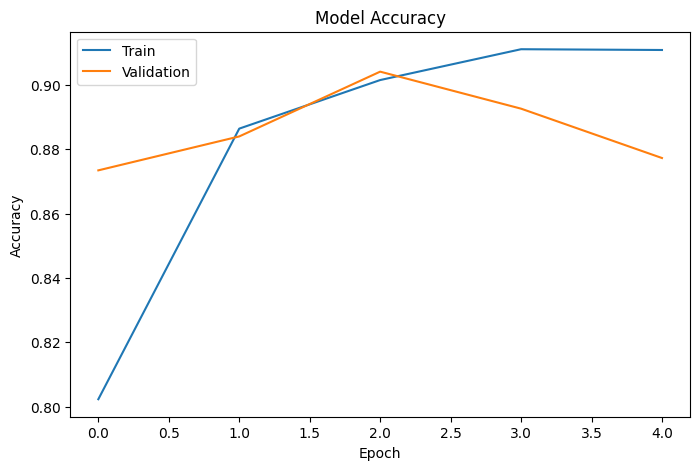

In [ ]:
# Plot accuracy

plt.figure(figsize=(8,5))

plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])

plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend(["Train","Validation"])

plt.show()

#8: Evaluate Model

In [ ]:
# Evaluate model on test data

loss, accuracy = model.evaluate(test_data)

print("Test Loss :", loss)
print("Test Accuracy :", accuracy)

20/20 ━━━━━━━━━━━━━━━━━━━━ 15s 723ms/step - accuracy: 0.8878 - loss: 0.2788
Test Loss : 0.2787720263004303
Test Accuracy : 0.8878205418586731


#9 Confusion Matrix

In [ ]:
# Predict classes

predictions = model.predict(test_data)

y_pred = (predictions > 0.5).astype("int32").flatten()

# Actual classes

y_true = test_data.classes

# Confusion matrix

cm = confusion_matrix(y_true, y_pred)

print(cm)

20/20 ━━━━━━━━━━━━━━━━━━━━ 13s 628ms/step
[[191  43]
 [ 27 363]]


# 10: Classification Report

In [ ]:
print(
    classification_report(
        y_true,
        y_pred,
        target_names=['NORMAL','PNEUMONIA']
    )
)

              precision    recall  f1-score   support

      NORMAL       0.88      0.82      0.85       234
   PNEUMONIA       0.89      0.93      0.91       390

    accuracy                           0.89       624
   macro avg       0.89      0.87      0.88       624
weighted avg       0.89      0.89      0.89       624



#11: Save Model

In [ ]:
# Save trained model

model.save("pneumonia_model.keras")

print("Model Saved Successfully")

Model Saved Successfully


#12: Prediction on New X-Ray Image


In [ ]:
!pip install tensorflow keras

In [ ]:
import numpy as np
from tensorflow.keras.preprocessing import image

# Load saved model

model = tf.keras.models.load_model(
    "pneumonia_model.keras"
)

# Upload image

img_path = "/content/sample image.jpg"

# Load image

img = image.load_img(
    img_path,
    target_size=(150,150)
)

# Convert image into array

img_array = image.img_to_array(img)

# Normalize

img_array = img_array / 255.0

# Add extra dimension

img_array = np.expand_dims(
    img_array,
    axis=0
)

# Prediction

prediction = model.predict(img_array)

if prediction[0][0] > 0.5:
    print("PNEUMONIA DETECTED")
else:
    print("NORMAL")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 460ms/step
NORMAL


#webpage creation

#1. Install packages (Streamlit)

In [ ]:
!pip install streamlit

  Using cached streamlit-1.58.0-py3-none-any.whl.metadata (9.6 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 18.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.3/11.3 MB 27.9 MB/s eta 0:00:00


#2. Save this as app.py

In [ ]:
# app.py
%%writefile app.py
import streamlit as st
import numpy as np
import tensorflow as tf
from PIL import Image

# Load trained model
model = tf.keras.models.load_model("pneumonia_model.keras")

IMG_SIZE = 150

# Page title
st.title("🫁 Medical Image Diagnosis System")

st.write("""
Upload a Chest X-Ray image and the model will predict whether
the patient has Pneumonia or is Normal.
""")

# Upload image
uploaded_file = st.file_uploader(
    "Choose an X-Ray Image",
    type=["jpg", "jpeg", "png"]
)

if uploaded_file is not None:

    # Display image
    image = Image.open(uploaded_file)

    st.image(
        image,
        caption="Uploaded X-Ray",
        use_container_width=True
    )

    # Convert image to RGB
    image = image.convert("RGB")

    # Resize image
    image = image.resize((IMG_SIZE, IMG_SIZE))

    # Convert image to array
    img_array = np.array(image)

    # Normalize
    img_array = img_array / 255.0

    # Add batch dimension
    img_array = np.expand_dims(
        img_array,
        axis=0
    )

    # Prediction button
    if st.button("Predict"):

        prediction = model.predict(img_array)

        confidence = prediction[0][0]

        st.subheader("Prediction Result")

        if confidence > 0.5:

            st.error("⚠️ PNEUMONIA DETECTED")

            st.write(
                f"Confidence Score: {confidence:.2%}"
            )

        else:

            st.success("✅ NORMAL")

            st.write(
                f"Confidence Score: {(1-confidence):.2%}"
            )

Writing app.py


#install packages

In [ ]:
! npm install -g cloudflared

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴
changed 1 package in 3s
⠴

#3. Run the App


In [ ]:
! streamlit run app.py &>/content/logs.txt &

In [ ]:
!cloudflared tunnel --url localhost:8501

2026-06-19T07:33:22Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-06-19T07:33:22Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-06-19T07:33:27Z INF +--------------------------------------------------------------------------------------------+
2026-06-19T07:33:27Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-06-19T07:33:27Z INF |  https://suite-tiles-manually-yellow.trycloudflare.com